# `PREDICTION DU CANCER DE SEIN`


### `Présentation du projet`

Le cancer du sein est l’un des cancers les plus fréquents chez la femme et constitue un enjeu majeur de santé publique. Le diagnostic repose généralement sur des examens d’imagerie médicale et des biopsies ; toutefois, ces approches peuvent être invasives, coûteuses et longues. Ce projet vise à prédire si une patiente est atteinte ou non d’un cancer du sein à l'aide des informations issues de bioptie. Il est important de préciser que les résultats obtenus dans ce projet ne peuvent être utilisés directement. Il s'agit bien d'un projet à caractère pédagogique. 


### `Problématique` 

La question à laquelle nous souhaitons répondre est la suivante :  

Peut-on prédire efficacement si une patiente est à risque ou pas à partir des caractéristiques morphologiques extraites d’images de biopsies ? Pour répondre à cette question, nous utilisons des méthodes scientifiques éprouvées et une démarche rigoureuse.


### `Objectifs liés aux performances` 

Nous travaillons sur un problème de classification binaire. Selon les premières informations sur notre jeu de données, celui-ci présent un déséquilibré au niveau de notre variables d'intérêt. Cette observation est essentielle pour le choix de nos métriques.  

Dans ce contexte, nous considérons plus les métriques suivantes : 

- Le **recall/sensitivity** : taux de cas positifs détectés. Cette métrique est prioritaire ici, car il s’agit d’un problème crucial (cancer du sein).
  L’objectif est de réduire significativement les faux négatifs (prédire faux mais vrai en réalité).
    
- La **precision** : proportion de cas prédits positifs qui sont réellement positifs.

- Le **F1-score** : utile pour contrôler le compromis précision/recall.

- La **specificity** : taux de cas négatifs détectés. 


Nos objectifs chiffrés sont :  

- Recall ≥ **90 %**  (atteindre ce score serait déjà bien pour la production).

- Precision ≥ **90 %** (Arriver à détecter 90% des patientes réellement atteintes du cancer de sein)

- F1-score ≥ **90 %**


### `Présentation du jeu de données` 

Le jeu de données utilisé provient du [Wisconsin Breast Cancer Dataset (WBCD)](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data) et contient 569 observations. 
Il est important de souligner que le nombre de points dans le dataset est assez faible pour prétendre industrialiser ce modèle pour un cas d'usage réel. 


### `Notre target`

- **diagnosis** : variable binaire avec deux modalités {B = Pas de cancer et M = Présence de cancer}.


### `Variables explicatives (30 au total)` 

Ces variables décrivent des caractéristiques géométriques et texturales des noyaux cellulaires mesurées à partir d’images de biopsies :  

- Moyenne des mesures (ex. `radius_mean`, `texture_mean`)

- Écart-type des mesures (ex. `radius_se`, `texture_se`)

- Valeurs extrêmes (“worst”) (ex. `radius_worst`, `texture_worst`)  

**Petite précision** : Nous travaillons principalement sur les variables relatives aux valeurs extrèmes mesurées.  


### `Idée de base sur le cancer du sein`

La littérature scientifique souligne que la distinction entre une tumeur bénigne et maligne repose sur l'atypie nucléaire. 
Alors que les noyaux des cellules saines ou bénignes tendent à être petits, réguliers et uniformes, les cellules cancéreuses présentent des altérations morphologiques marquées dues à une prolifération anarchique.


`Author : @Madiba`


---

### `Analyse Exploratoire des données`

### `Objectif`
- Comprendre du mieux que possible nos données.
- Développer une prémière stratégie de modélisation. 


### `Checklist de base`

**Analyse de forme** : 

- Variable target : `diagnosis`
- Lignes et colonnes : 569, 31
- Types de variables : quantitatives (30), qualitative (1)
- Analyse des valeurs manquantes : Aucune valeur manquante
- Données duplicées : Aucun doublon


**Analyse de Fond** : 

- Visualisation de la target : 36% de cas positifs (variable déséquilibrée)
  
- Signification des variables : Nous constatons dans un premier temps que les varibales numériques n'ont pas été standardisées, une différence d'échelle très grande.
  Ces variables dans leur ensemble présentent une distribution assymétrique positive (plus étirée vers la droite).

- Relation variables/Target : L'examen des distributions croisées permet d'identifier un groupe de variables hautement discriminantes : radius_worst, perimeter_worst, area_worst,
concavity_worst et concave_points_worst.



---

### `Analyse de forme`

In [1]:
# Librairies 
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 
import os 


In [2]:
# repertoire de travail actuel ?
os.getcwd()

'C:\\Users\\LENOVO\\Desktop\\Docker-Compose-Tuto\\Notebook'

In [3]:
# Changer le repertoire de travail
os.chdir("..")
os.getcwd()

'C:\\Users\\LENOVO\\Desktop\\Docker-Compose-Tuto'

In [4]:
# Importation des données depuis Data/raw/
cancer = pd.read_csv("Data/raw/cancer.csv", sep=",")


In [5]:
# Les Cinq premières lignes du dataset 
cancer.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
# Supprimer les colonnes "id" et "Unnamed: 32" 
cancer = cancer.drop(["id", "Unnamed: 32"], axis=1)

In [7]:
# Dimension du dataset avant modification : (569, 31)
cancer.shape

(569, 31)

In [8]:
# Type de données : float64 30 / object 1
cancer.dtypes.value_counts()

float64    30
object      1
Name: count, dtype: int64

In [9]:
# Présence de données manquantes ? ===> Aucune données manquante détectée.
cancer.isna().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

---

In [10]:
# Sélection des variables "worst" ==> il s'agit des valeurs extrèmes mésurées. 

col_mean_list = [] 

for col in cancer.columns: 
    if "worst" in col or col == "diagnosis" : 
        col_mean_list.append(col)
        
cancer_new = cancer[col_mean_list]


# 8 premières lignes du nouveau dataset 
cancer_new.head(8)


,diagnosis,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,M,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,M,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510


In [11]:
# Nouvelle dimension du dataset cancer_new : (569, 11)
cancer_new.shape

(569, 11)

In [12]:
# Renommer la variable "concave points_worst"
cancer_new = cancer_new.rename(columns={"concave points_worst":"concave_points_worst"})

In [13]:
# Données dupliquées ? ===> Pas de données dupliquées 
cancer_new.loc[cancer_new.duplicated()]

,diagnosis,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst


---

### `Analyse de fond`

#### `Détection d'outliers par la méthode des quantiles`

In [14]:
# Détection de outiliers pour une variable particulière.

outliers_dict = {} 

# Calcul des quantiles.
for col in cancer_new.select_dtypes(include='float').columns:
    Q1 = cancer_new[col].quantile(0.25)
    Q3 = cancer_new[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # bornes
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # indices des outliers
    outliers = cancer_new[(cancer_new[col] < lower_bound) | (cancer_new[col] > upper_bound)].index
    
    outliers_dict[col] = outliers.tolist()


In [15]:
# Essaayons avec les variables suivantes : radious_worst, perimeter_worst et area_worst 

# Outliers pour la variable "radius_mean" ? ===> 17 outliers 
print("Outliers détectés :", outliers_dict["radius_worst"], "----->", "Nombre outliers :", len(outliers_dict["radius_worst"]))


Outliers détectés : [23, 82, 108, 164, 180, 212, 219, 236, 265, 272, 339, 352, 368, 369, 461, 503, 521] -----> Nombre outliers : 17


In [16]:
# Outliers pour la variable "perimeter_mean" ? ===> 15 outliers 
print("Outliers détectés :", outliers_dict["perimeter_worst"], "----->", "Nombre outliers :", len(outliers_dict["perimeter_worst"]))


Outliers détectés : [23, 82, 108, 180, 212, 236, 265, 272, 339, 352, 368, 369, 461, 503, 521] -----> Nombre outliers : 15


In [17]:
# Outliers pour la variable "area_mean" ? ===> 35 outliers 
print("Outliers détectés :", outliers_dict["area_worst"], "----->", "Nombre outliers :", len(outliers_dict["area_worst"]))


Outliers détectés : [0, 1, 18, 23, 24, 56, 82, 108, 122, 162, 164, 180, 181, 202, 212, 218, 219, 236, 250, 254, 265, 272, 300, 323, 339, 352, 368, 369, 373, 393, 449, 461, 503, 521, 564] -----> Nombre outliers : 35


---

**Note** : Ici, nous notons que les variables `radius_mean` et `perimeter_mean` partagent quasiment les mêmes d'outliers. 
Ils contiennent respectivement 17 et 15 outliers. Pour la variable `area_mean`, 35 potentiels outliers ont été détecté. Essayons avec l'algorithme d'isolation forest pour détecter les une sorte d'anomalie dans nos données. 

---

#### `Détection d'outliers par la méthode d'isolation de forêt`

In [19]:
# Import IsolationForest
from sklearn.ensemble import IsolationForest

In [20]:
# construire X et y  
X = cancer_new.drop("diagnosis", axis=1)
y = cancer_new["diagnosis"]

In [21]:
 # Entrainement de l'algo : avec les paramètres initiaux.
model_iso = IsolationForest(contamination = 0.02 , n_estimators=500, random_state = 2)
model_iso.fit(X)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",500
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.02
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary ` for more details.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",2
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary `... versionadded:: 0.21",False


#### `Visualisation des ouliers`

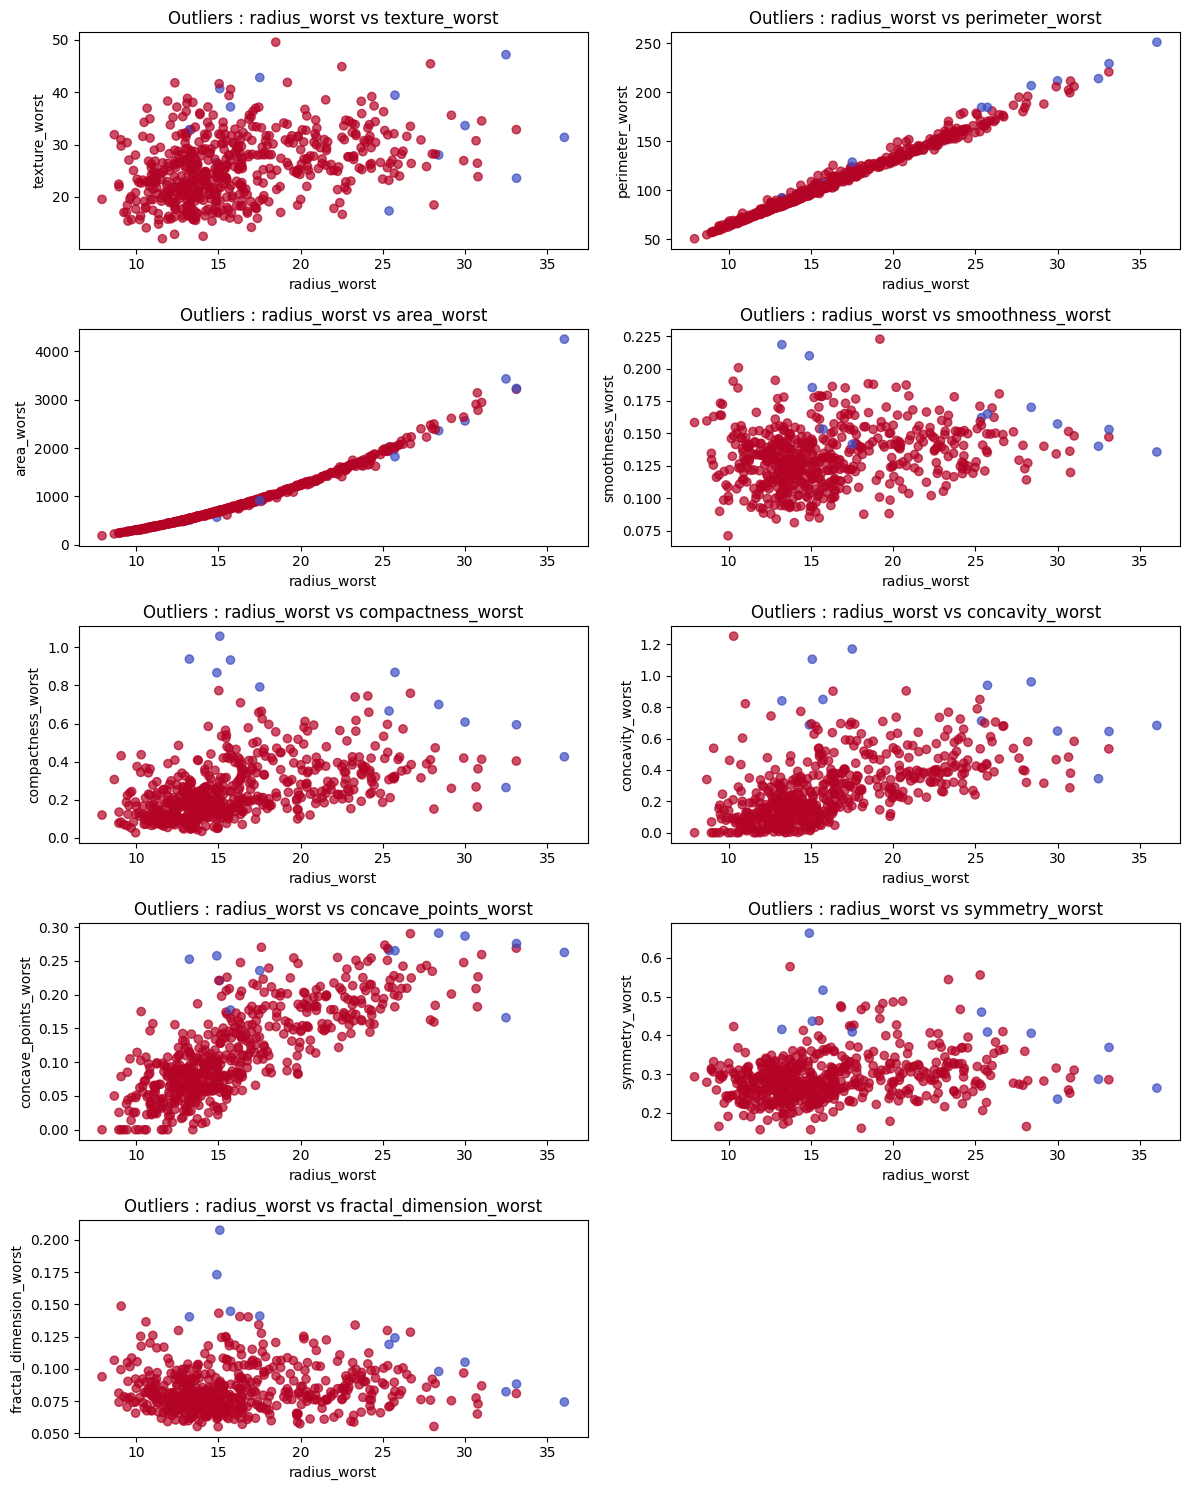

In [22]:

cols_isoforest = [col for col in cancer_new.select_dtypes(include='float').columns if col != "radius_worst"]

# Parametres d'affichage graphique 
ncols = 2  
nrows = (len(cols_isoforest) + 1) // ncols   


fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 3*nrows))

# config graphique 
axes = axes.flatten()

for i, col in enumerate(cols_isoforest):
    ax = axes[i]
    ax.scatter(
        X["radius_worst"],
        X[col],
        c=model_iso.predict(X), # isolationForest predict
        cmap="coolwarm",
        alpha=0.7
    )
    ax.set_title(f"Outliers : radius_worst vs {col}")
    ax.set_xlabel("radius_worst")
    ax.set_ylabel(col)

# Supprimer les axes vides si le nombre de variables n'est pas pair
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


- Comment fonctionne l'algorithme d'isolation forest ? ===> lien suivant : [how isolation forest works](https://www.geeksforgeeks.org/machine-learning/what-is-isolation-forest/)

#### `Suppression des outliers`

In [23]:
# Identifier les données non outliers (normales). 
non_outliers = model_iso.predict(X) != -1

In [24]:
# Suppression des outliers du dataset.
cancer_clean = cancer_new[non_outliers]

In [25]:
# Combien d'outliers supprimés ? ===> Seulement 12 points supprimés soit 2% du dataset initial. 
print("Nombre d'outliers supprimés : ", cancer.shape[0] - cancer_clean.shape[0])

Nombre d'outliers supprimés :  12


In [26]:
# Nouvelle dimension cancecancer_clean : (557, 11)
cancer_clean.shape

(557, 11)

---


### `Analyse exploratoire des données`

### `Analyse univariée`

#### `Variable cible`

In [27]:
# Quelle proportion de personnes malade ? ===> 36% des patientes examinées sont atteintes du cancer de seins. 
cancer_clean["diagnosis"].value_counts(normalize=True)

diagnosis
B    0.640934
M    0.359066
Name: proportion, dtype: float64

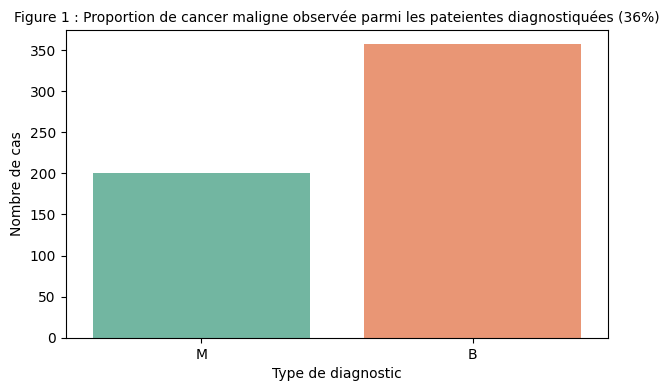

In [28]:
# Nombre de cas positif en image 

plt.figure(figsize=(7, 4))
sns.countplot(
    data=cancer_clean,
    x="diagnosis",
    hue="diagnosis",    
    palette="Set2",
    legend=False)

plt.title("Figure 1 : Proportion de cancer maligne observée parmi les pateientes diagnostiquées (36%)", fontsize=10)
plt.xlabel("Type de diagnostic")
plt.ylabel("Nombre de cas")
plt.show()


---

#### `Description des caractéristiques numériques` 

#### `Histogrammes`  

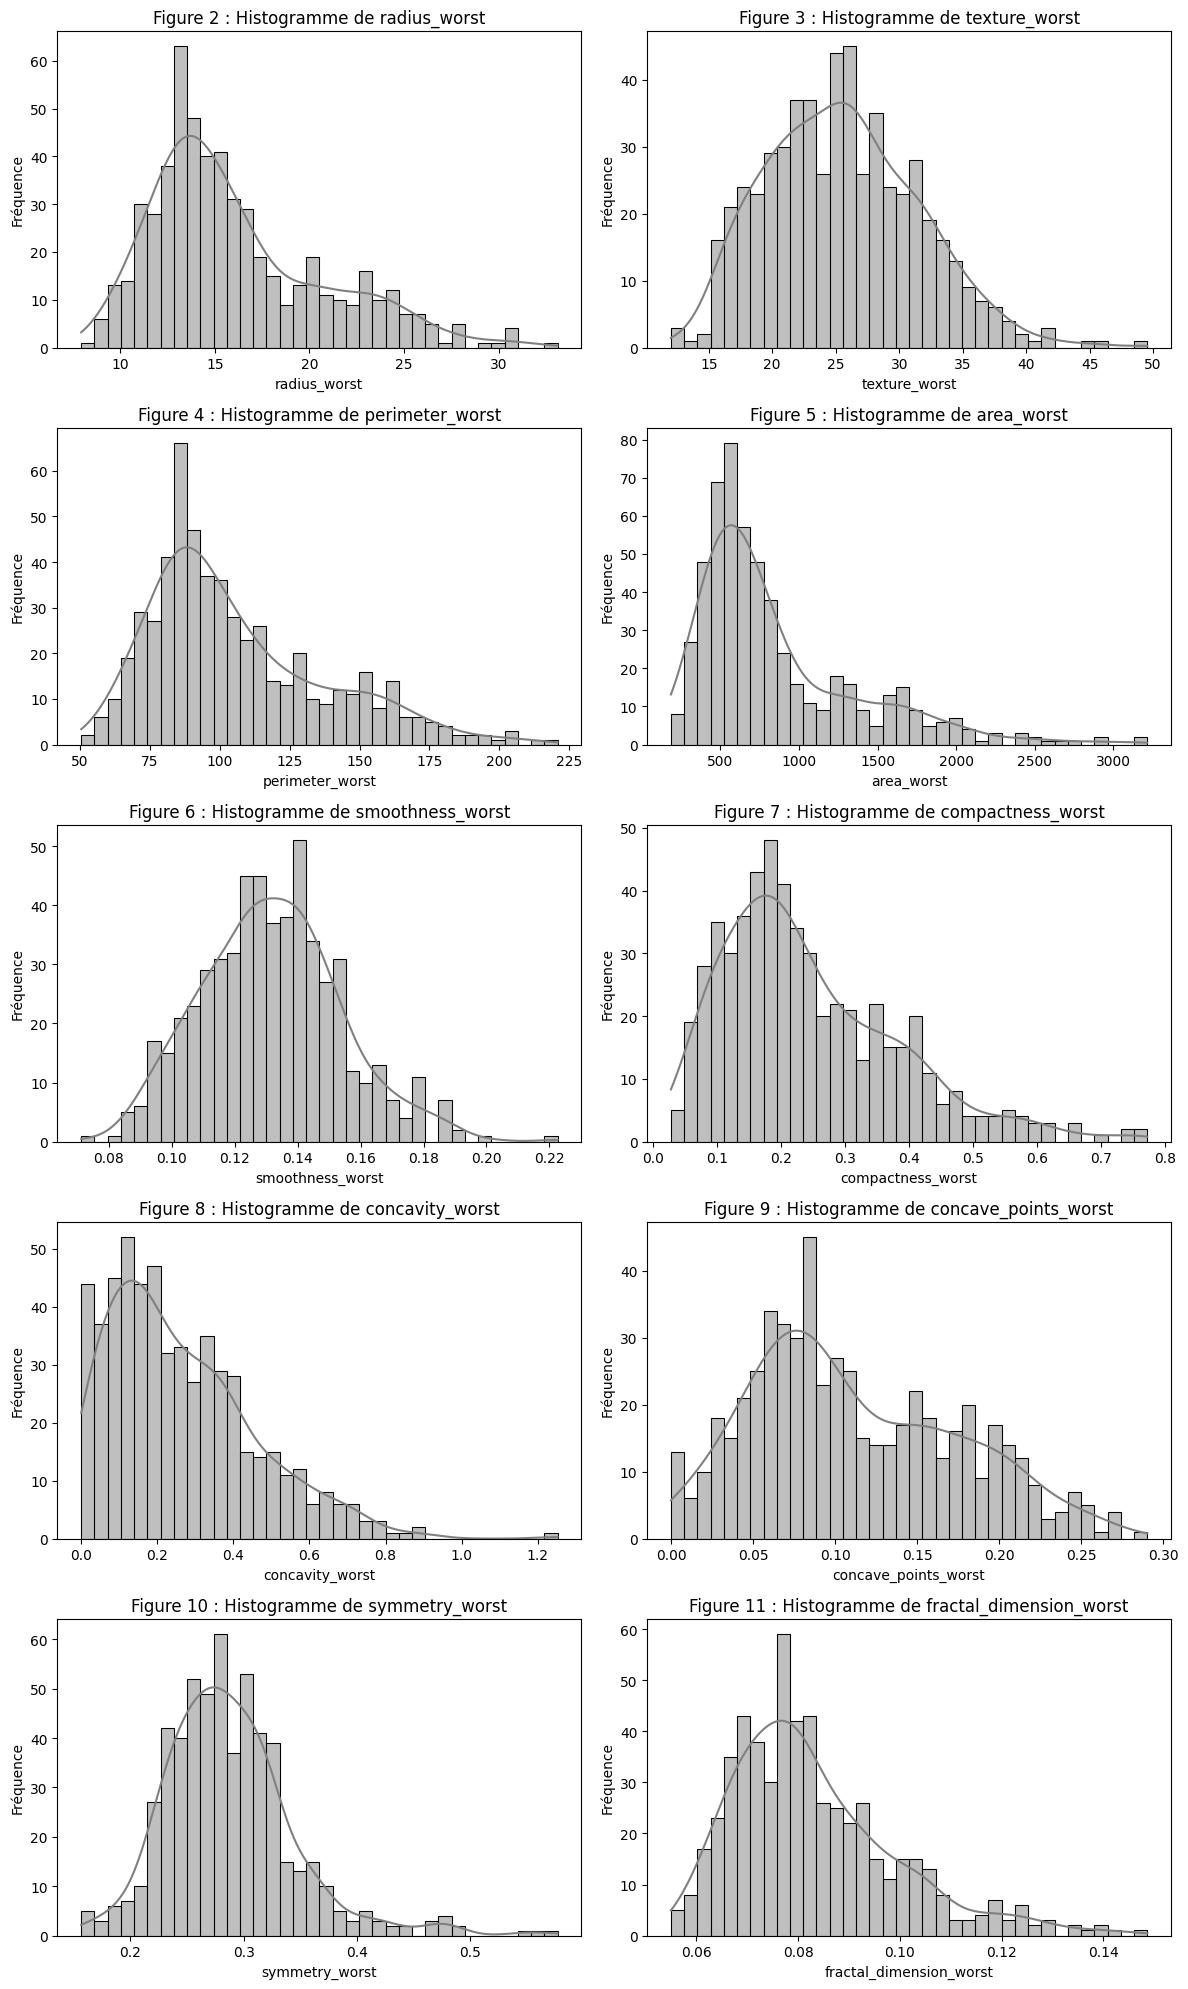

In [29]:
# Liste des colonnes numériques
cols = cancer_clean.select_dtypes(include='float').columns

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4*nrows))
axes = axes.flatten()  

for idx, col in enumerate(cols, start=2):
    ax = axes[idx-2]  
    sns.histplot(
        cancer_clean[col],
        kde=True,
        bins=int(180/5),
        color='gray',
        ax=ax
    )
    ax.set_title(f"Figure {idx} : Histogramme de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

# Supprimer les axes vides si le nombre de variables est impair
for j in range(idx-1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show() 


---

#### `Target vs Features`

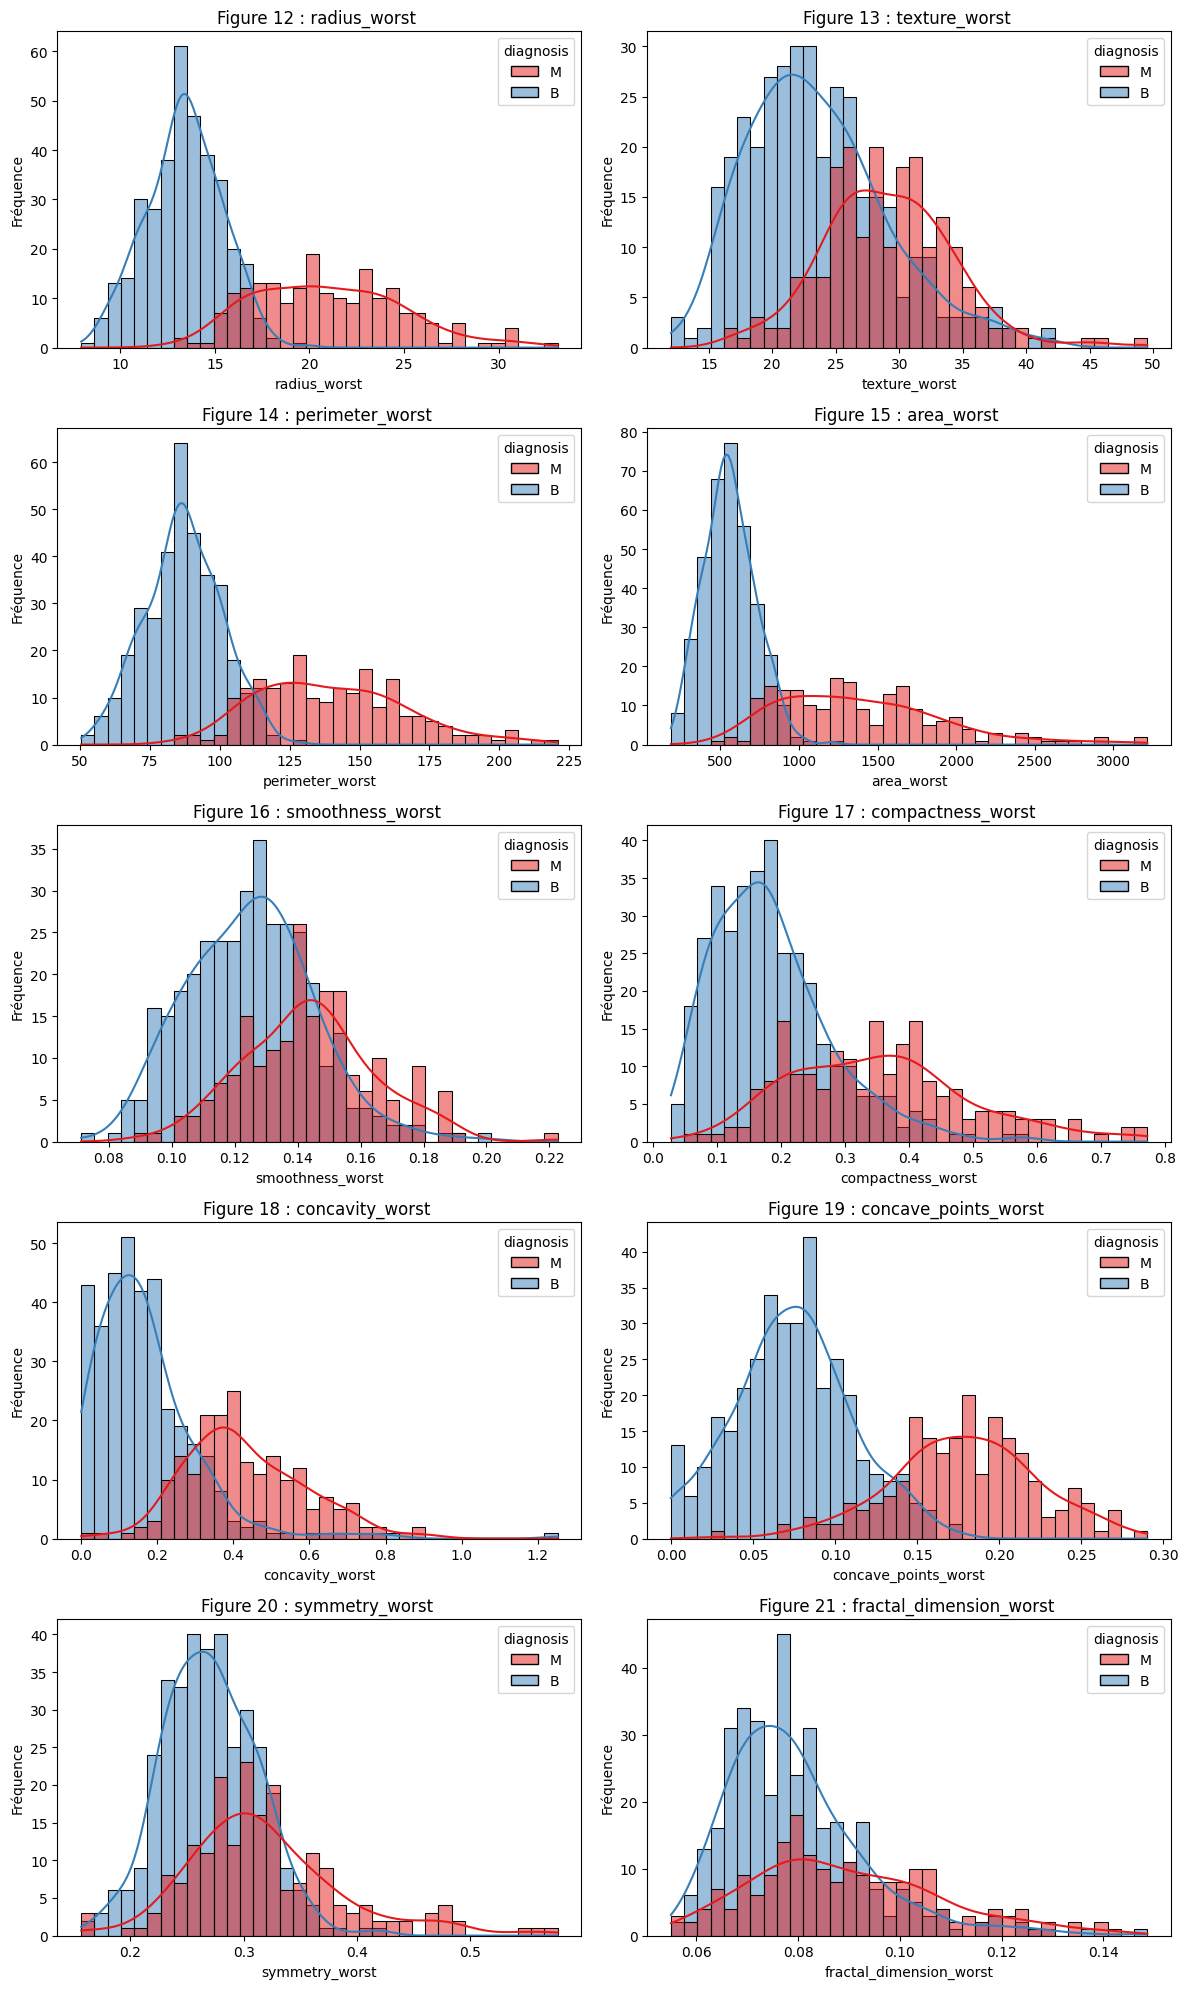

In [30]:
# Liste des colonnes numériques
cols = cancer_clean.select_dtypes(include='float').columns

ncols = 2
nrows = (len(cols) + ncols - 1) // ncols   

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 4*nrows))
axes = axes.flatten()  


for idx, col in enumerate(cols, start=12):
    ax = axes[idx-12]  
    sns.histplot(
        data=cancer_clean,
        x=col,
        hue="diagnosis",
        kde=True,
        bins=int(180/5),
        palette="Set1",
        alpha=0.5,
        ax=ax
    )
    ax.set_title(f"Figure {idx} : {col} ")
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

# Supprimer les axes vides si le nombre de variables est impair
for j in range(idx-11, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


`Note` : L'examen des distributions croisées permet d'identifier un groupe de variables hautement discriminantes : `radius_worst`, `perimeter_worst`, `area_worst`, `concavity_worst` et `concave_points_worst`. Pour ces indicateurs, on observe une séparation nette entre les deux classes. D'un point de vue clinique, ces graphiques valident l'hypothèse suivante : plus les valeurs liées à la taille (aire, rayon) et à l'irrégularité des contours (concavité) sont élevées, plus la probabilité que la tumeur soit maligne augmente. À l'inverse, les tumeurs bénignes se concentrent systématiquement dans des zones de valeurs faibles et homogènes, caractéristiques de cellules stables et régulières. Les variables `radius_worst` et `perimeter_worst` présentent quasiment les mêmes distributions. Dans la séction, nous réaliserons un pairplot pour comprendre les rélation entre toutes les variables numérique. 

---

### `Analyse bivariée`

#### `Pairs plots`

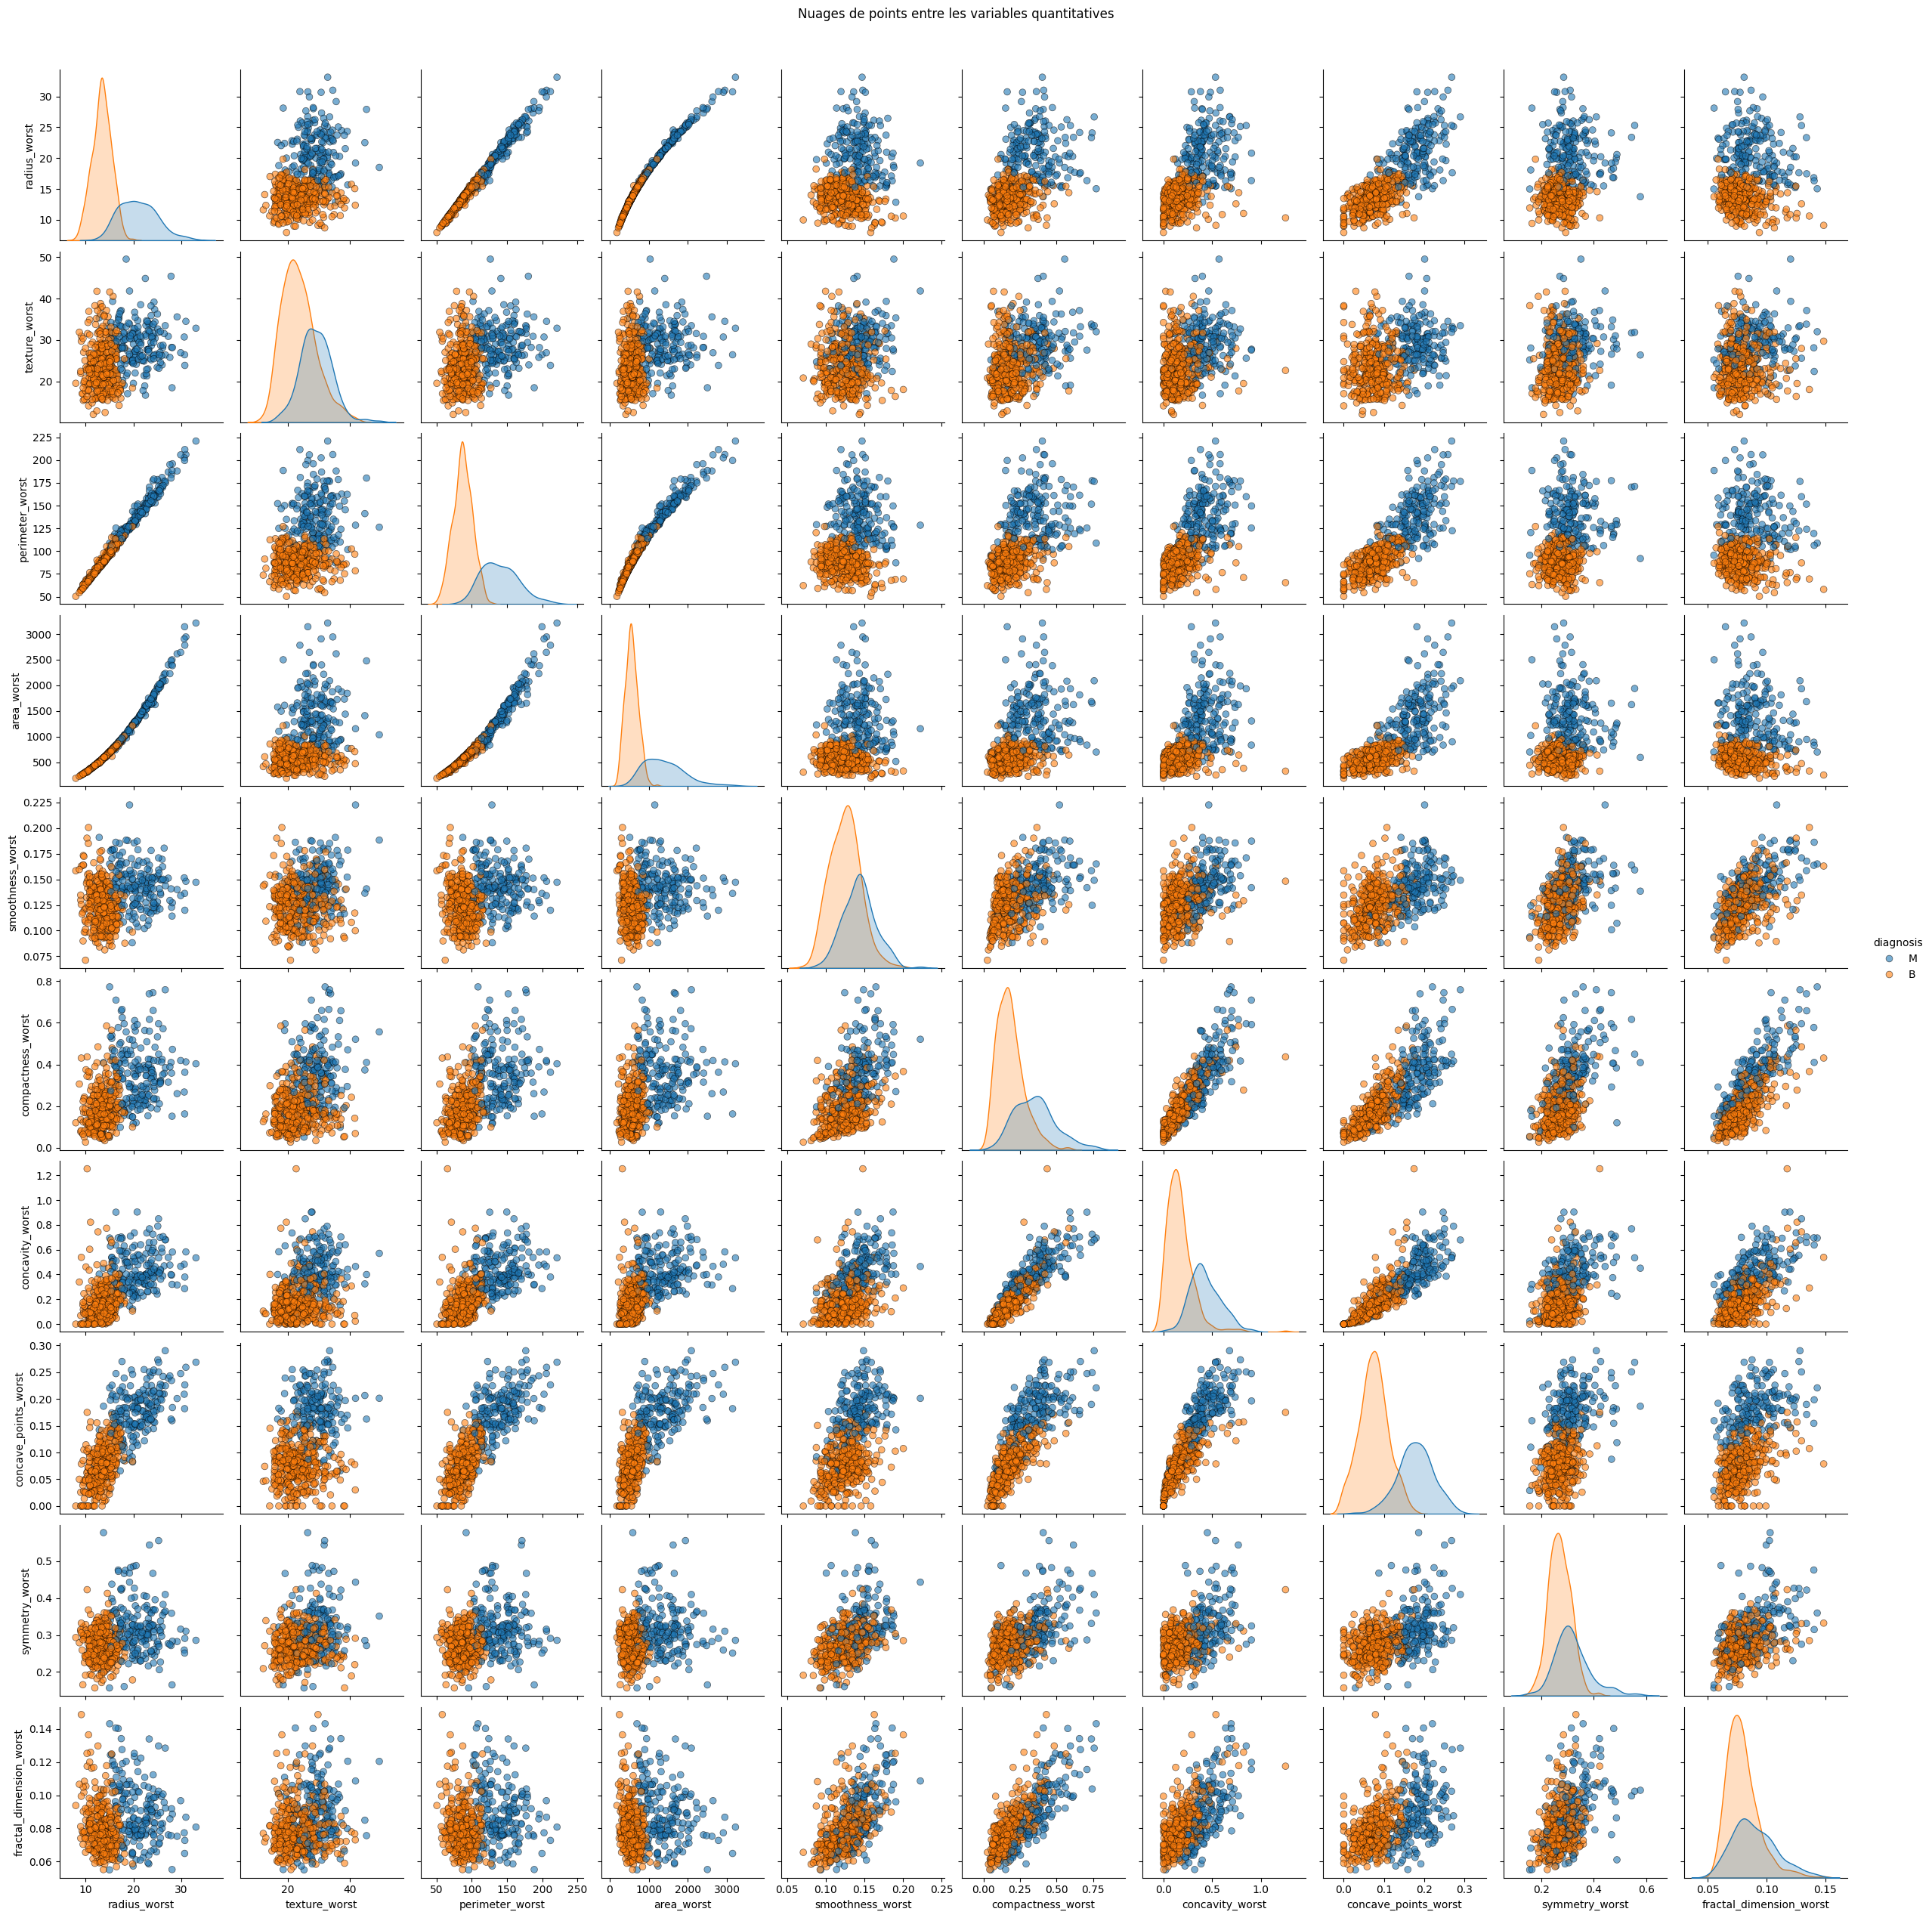

In [31]:
# Liste des colonnes numériques
cols = cancer_clean.select_dtypes(include='float').columns.tolist()

# Ajouter la variable cible
cols.append("diagnosis")

# Pairplot
sns.pairplot(
    cancer_clean[cols],
    diag_kind="kde",
    hue="diagnosis",
    plot_kws={"alpha": 0.6, "s": 40, "edgecolor": "k"}
)

plt.suptitle("Nuages de points entre les variables quantitatives", y=1.02)
plt.show()

---

### `Tests de corrélation`  

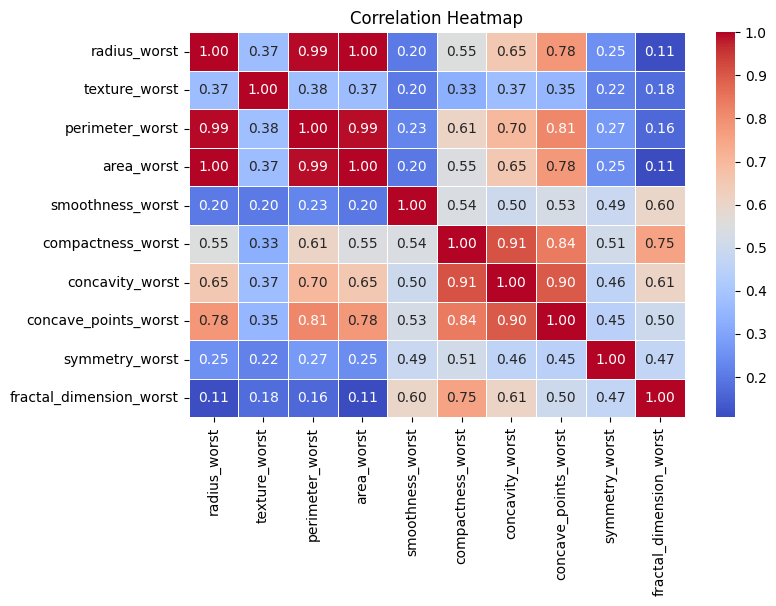

In [32]:
## Présence de forte corrélation ? ===> Oui, coéfficient de corrélation supérieur à 95%.  
cancer_cor = cancer_clean.drop("diagnosis", axis=1).corr(method='spearman', )

# Heatmap
plt.figure(figsize=(8,5))
sns.heatmap(cancer_cor, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.7)
plt.title("Correlation Heatmap")
plt.show()


----

Le test de corrélation qui à pour objectif de tester la relation linéaire entre deux variables quantitatives suggère une relation linéaire très forte entre les variables : 

- radius_worst et area_worst (r= 1) == > Cependant, cette relation ressemble plus à une relation polynomiale que linéaire.
- radius_worst et perimeter (r=0.99) ==> relation linéaire parfaite.
- area_worst et perimeter (0.99) ==> realtion linéaire parfaite. 

---

### `Nuage de points`

- radius_worst vs area_worst
- radius_worst vs perimeter_worst
- area_worst vs perimeter_worst
- concavity_worst vs concave_points_worst
- concavity_worst vs compactness_worst 

In [33]:
def plot_multi_scatter(df, vars_list, n_cols=2, alpha=0.7, reg_color="red"):
   
    x_var = vars_list[0]
    y_vars = vars_list[1:]

    n_plots = len(y_vars)
    n_rows = (n_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    axes = axes.flatten()

    for ax, y in zip(axes, y_vars):
        # Scatter
        sns.scatterplot(data=df, x=x_var,y=y, alpha=alpha,ax=ax)

        # Régression
        sns.regplot(data=df,x=x_var, y=y,scatter=False,color=reg_color,ax=ax)

        ax.set_title(f"{x_var} vs {y}")

    # Masquer les axes inutilisés
    for ax in axes[n_plots:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()
    

In [34]:
from itertools import combinations

def plot_multi_scatter(df, vars_list, n_cols=2, alpha=0.7, reg_color="red"):

    # Générer toutes les combinaisons (x, y)
    combos = list(combinations(vars_list, 2))
    n_plots = len(combos)

    # Déterminer le nombre de lignes
    n_rows = (n_plots + n_cols - 1) // n_cols

    # Créer la figure
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    axes = axes.flatten()

    # Boucle sur les combinaisons
    for ax, (x_var, y_var) in zip(axes, combos):

        # Scatter
        sns.scatterplot(data=df, x=x_var, y=y_var, alpha=alpha, ax=ax)

        # Régression
        sns.regplot(data=df, x=x_var, y=y_var, scatter=False, color=reg_color, ax=ax)
        ax.set_title(f"{x_var} vs {y_var}")

    # Masquer les axes inutilisés
    for ax in axes[n_plots:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

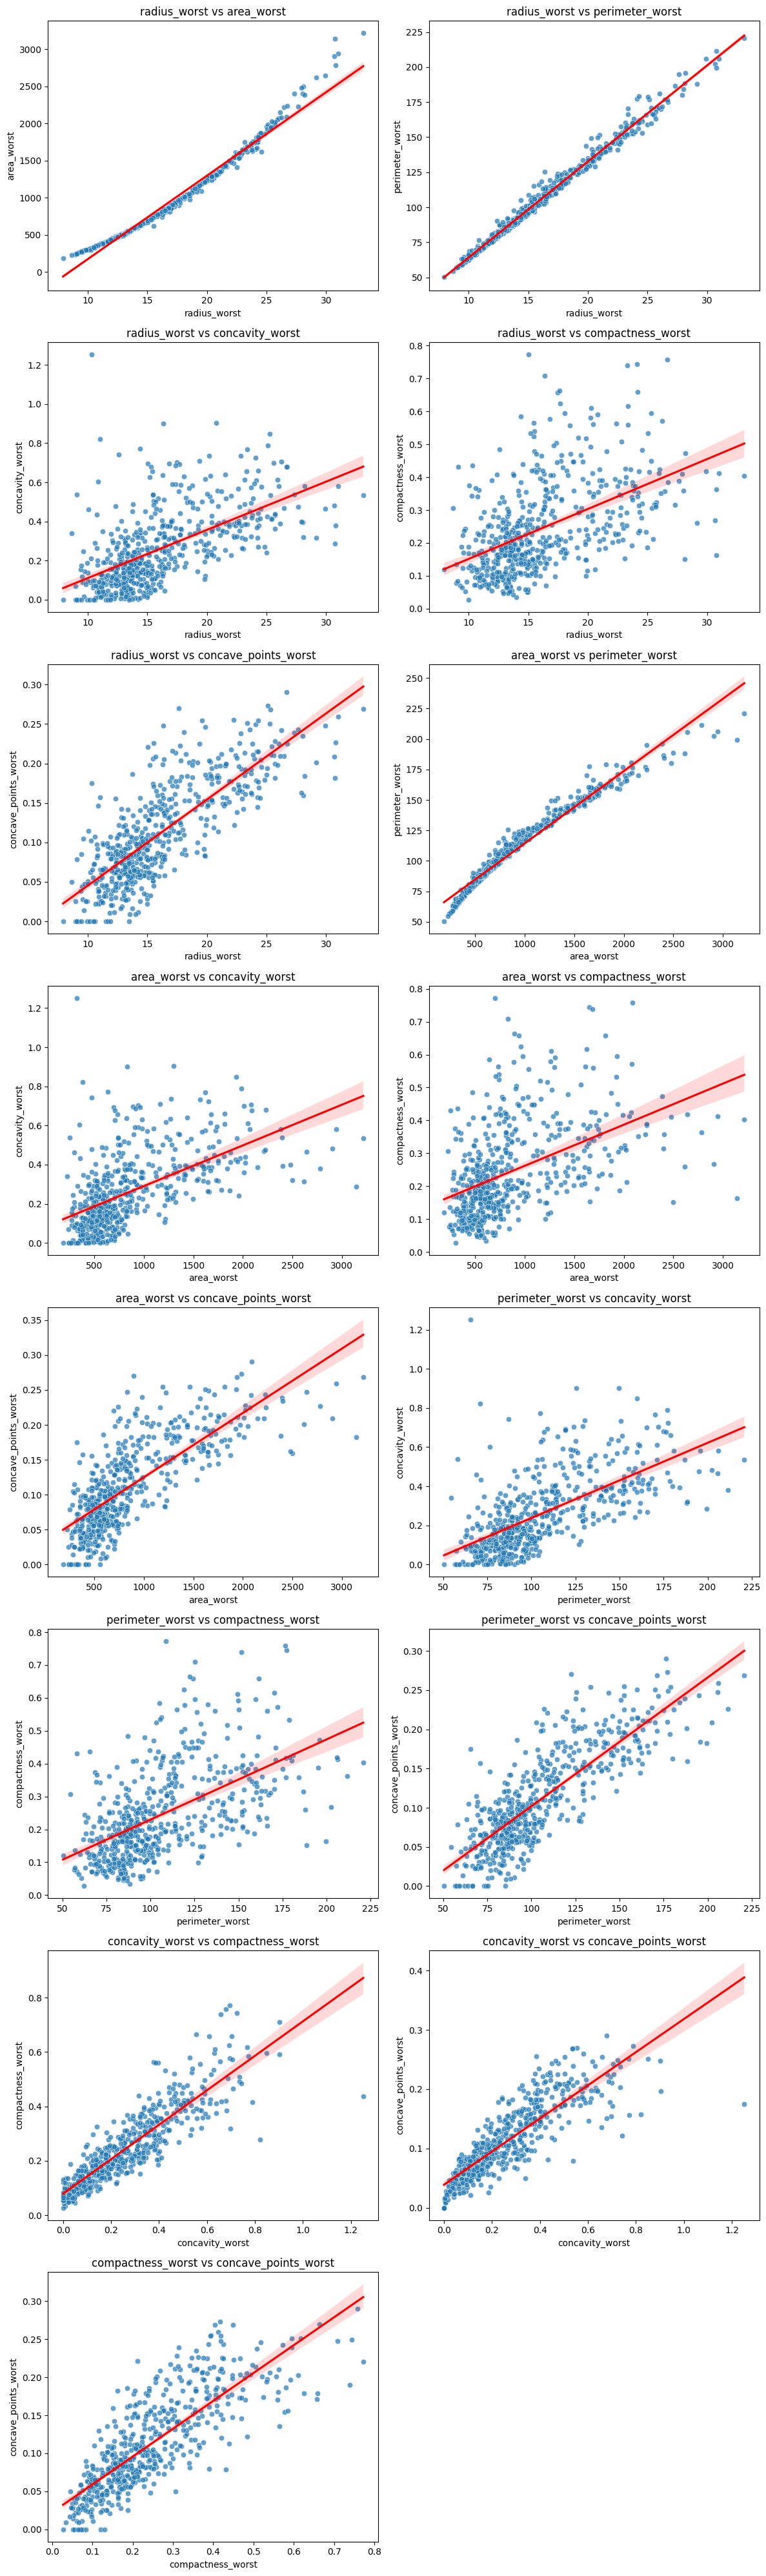

In [35]:
vars_list = ["radius_worst", "area_worst", "perimeter_worst","concavity_worst", "compactness_worst", "concave_points_worst"]
plot_multi_scatter(df=cancer_clean, vars_list=vars_list)

**Note** :

Relations très fortes (corrélation > 0.97) :

- `area_mean` <-> `radius_mean` : 0.999591
- `perimeter_mean` <-> `radius_mean` : 0.997804		
- `area_mean` <-> `perimeter_mean` : 0.997115

Corrélations fortes (0.93 > corrélation > 0.80)  : 

- `compactness_mean` <-> `concavity_mean` : 0.891928
- `compactness_mean` <-> `concave.points_mean` : 0.841146
- `Concavity_mean` <-> `concave.points_mean` : 0.923077


---


**Note** : 

Selon les résultats obtenus, les variables de forme, telles que `concavity_mean`, `concave_points_mean` et `compactness_mean`, ainsi que les variables de taille, telles que `area_mean`, `perimeter_mean` et `radius_mean`, semblent constituer des facteurs discriminants importants pour distinguer les patientes atteintes d’un cancer du sein. On peut noter également de fortes rélations entre plusieurs varibales avec des coéfficient r supérieurs à 93 voir 99.


**Points importants** : 

Dans ce jeu de données, nous ne disposons pas des informations liées à l’âge et aux habitudes de vie des patientes. Or, selon l’[Institut national du cancer](https://www.cancer.fr/), environ 80 % des cancers du sein sont diagnostiqués après l’âge de 50 ans, et les habitudes quotidiennes constituent des facteurs de risque importants. Ces informations pourraient-être importantes pour la performance du modèle de classification.


---

### `Test de narmalité`

In [36]:
# Test de normalité 
from scipy import stats

# Test
res = stats.normaltest(X)

# Résultats 
def test_normalite(X, res):
    
    # Associer colonnes et la statistique
    d = {col: stat for col, stat in zip(X.columns, res.statistic)}
    
    # Associer colonnes et p-values
    p = {col: pval for col, pval in zip(X.columns, res.pvalue)}

    # Fusionner en DataFrame
    df = pd.DataFrame({
        "Variable": X.columns,
        "Statistic": res.statistic,
        "pvalue": res.pvalue
        })
    
    return df

# Résultat
result = test_normalite(X, res)
result 

# H0 : les données suivent une distribution normale. 
# H1 : Les données ne suivent pas une distribution normale.
# Seuil de significativité : 5%
# Règle de décision : si p_value < seuil, alors on rejette H0 au risque alpha de se tromper. 


,Variable,Statistic,pvalue
0,radius_worst,91.750045,1.193248e-20
1,texture_worst,22.833847,1.100761e-05
2,perimeter_worst,96.555412,1.079590e-21
3,area_worst,222.965049,3.834907e-49
4,smoothness_worst,20.183782,4.141403e-05
5,compactness_worst,165.165161,1.364084e-36
6,concavity_worst,108.263932,3.095892e-24
7,concave_points_worst,33.727473,4.744302e-08
8,symmetry_worst,179.097146,1.286912e-39
9,fractal_dimension_worst,212.084252,8.840765e-47


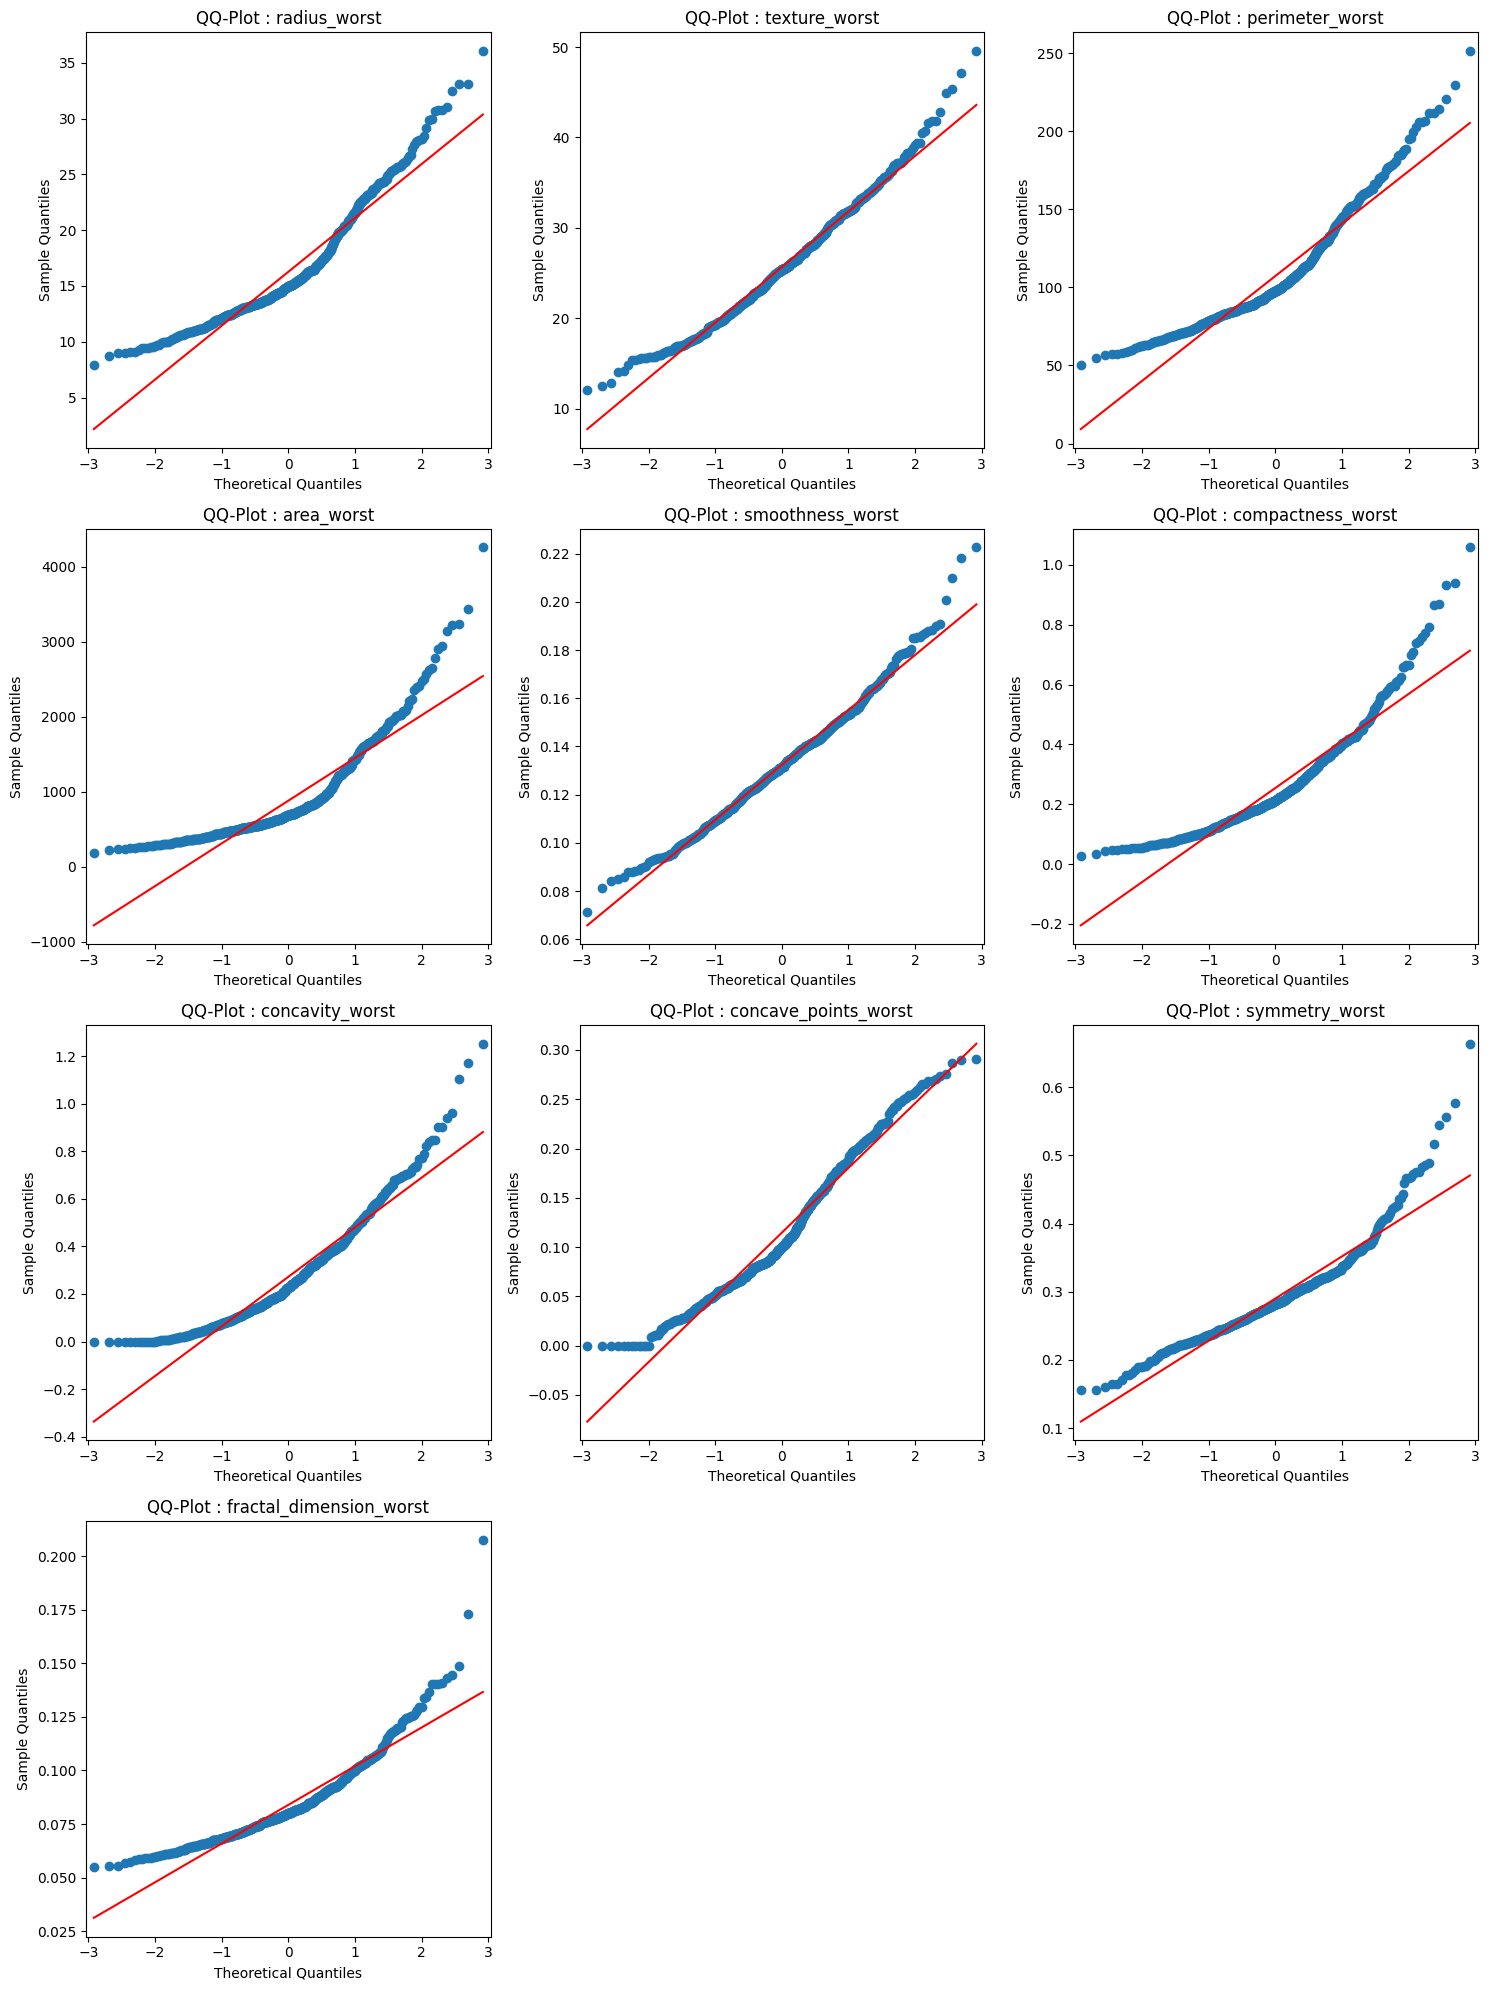

In [37]:
# QQplot 
import matplotlib.pyplot as plt
import statsmodels.api as sm
import math

# Nombre de variables
n_cols = 3
n_rows = math.ceil(len(X.columns) / n_cols)

# Taille de la figure
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))

# Aplatir les axes
axes = axes.flatten()

# Génération des QQ-plots
for i, col in enumerate(X.columns):
    sm.qqplot(
        X[col],
        line='s',
        ax=axes[i]
    )
    axes[i].set_title(f"QQ-Plot : {col}")

# Supprimer les axes inutiles
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Note** : Le test de normalité suggère de rejeter au seuil de 5% l'hypothèse nulle selon laquelle nos variables proviennent d'une distribution normale. Comme l'ont montré nos histogrammes et QQ-plots, les caractéristiques suivent une distribution asymétrique. Cette suggestion statistique nous oriente vers des tests non paramétriques pour la comparaison des classes B et M. 


---

### `Test de Mann-whitney`

In [38]:
from scipy.stats import mannwhitneyu

def mannwhitney_test(data, dep_var="diagnosis", alpha=0.05) :
   
    # Sélection des variables numériques
    num_vars = data.select_dtypes(include="number").columns.tolist()
    if dep_var in num_vars:
        num_vars.remove(dep_var)
    
    results = []
    
    # Boucle sur chaque variable numérique
    for var in num_vars:
        group1 = data.loc[data[dep_var] == "B", var].values
        group2 = data.loc[data[dep_var] == "M", var].values
        
        # Test Mann-Whitney
        stat, pval = mannwhitneyu(group1, group2, alternative="two-sided")
        
        # Rank biserial
        n1, n2 = len(group1), len(group2)
        rank_biserial = (2*stat)/(n1*n2) - 1
        
        # Interprétation
        if pval < alpha:
            if rank_biserial > 0:
                interpretation = "Significatif : Bénin > Malin"
            else:
                interpretation = "Significatif : Malin > Bénin"
        else:
            interpretation = "Non significatif"
        
        results.append({
            "Variable": var,
            "U_stat": stat,
            "p_value": pval,
            "RankBiserial": np.round(rank_biserial, 3),
            "Interpretation": interpretation
        })
    
    # Conversion en DataFrame
    results_df = pd.DataFrame(results)
    return results_df

    

In [39]:
results_df = mannwhitney_test(cancer_clean, dep_var="diagnosis")
results_df

,Variable,U_stat,p_value,RankBiserial,Interpretation
0,radius_worst,1842.5,4.560166e-77,-0.948,Significatif : Malin > Bénin
1,texture_worst,15583.0,2.444646e-28,-0.564,Significatif : Malin > Bénin
2,perimeter_worst,1554.0,2.357682e-78,-0.956,Significatif : Malin > Bénin
3,area_worst,1794.5,2.792783e-77,-0.950,Significatif : Malin > Bénin
4,smoothness_worst,18262.5,1.072225e-21,-0.488,Significatif : Malin > Bénin
5,compactness_worst,10357.5,5.661704e-44,-0.710,Significatif : Malin > Bénin
6,concavity_worst,5895.5,3.881903e-60,-0.835,Significatif : Malin > Bénin
7,concave_points_worst,2518.0,4.254107e-74,-0.929,Significatif : Malin > Bénin
8,symmetry_worst,19301.0,2.262878e-19,-0.459,Significatif : Malin > Bénin
9,fractal_dimension_worst,23299.0,1.006570e-11,-0.347,Significatif : Malin > Bénin


**Note** : Nous avons observé lors de l’analyse exploratoire qu’il existe un lien très fort entre certaines caractéristiques. C’est notamment le cas de `radius_mean`, `area_mean` et `perimeter_mean`, qui présentent des coefficients de corrélation supérieurs à 0,97. De même, plusieurs caractéristiques liées à la forme comme `compactness_mean`, `concavity_mean` et `concave.points_mean` montrent également une corrélation élevée entre elles. Dans le cadre de la sélection des variables, nous avons aussi tenir compte du test de Mann Withney. Ce test non parametrique nous a permis de sélectionner les caractérisque en se basant sur la force de son lien avec notre variable cible.


---

### `Sélection de variables `

#### `Méthode de variance` 

---

In [40]:
from sklearn.feature_selection import VarianceThreshold

# Calcul des variances
variance = X.var()

# DataFrame des variances
variance_df = pd.DataFrame({
    "Variable": X.columns,
    "Variance": variance.values
})

# Tri décroissant
variance_df = variance_df.sort_values(by="Variance", ascending=False)

print(variance_df)

                  Variable       Variance
3               area_worst  324167.385102
2          perimeter_worst    1129.130847
1            texture_worst      37.776483
0             radius_worst      23.360224
6          concavity_worst       0.043524
5        compactness_worst       0.024755
7     concave_points_worst       0.004321
8           symmetry_worst       0.003828
4         smoothness_worst       0.000521
9  fractal_dimension_worst       0.000326


---

#### `Méthode LASSO`

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

lasso = LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)

selector = SelectFromModel(lasso)
selector.fit(X, y)

selected_features = X.columns[selector.get_support()]

print(selected_features)

Index(['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
       'compactness_worst', 'concavity_worst'],
      dtype='object')


C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


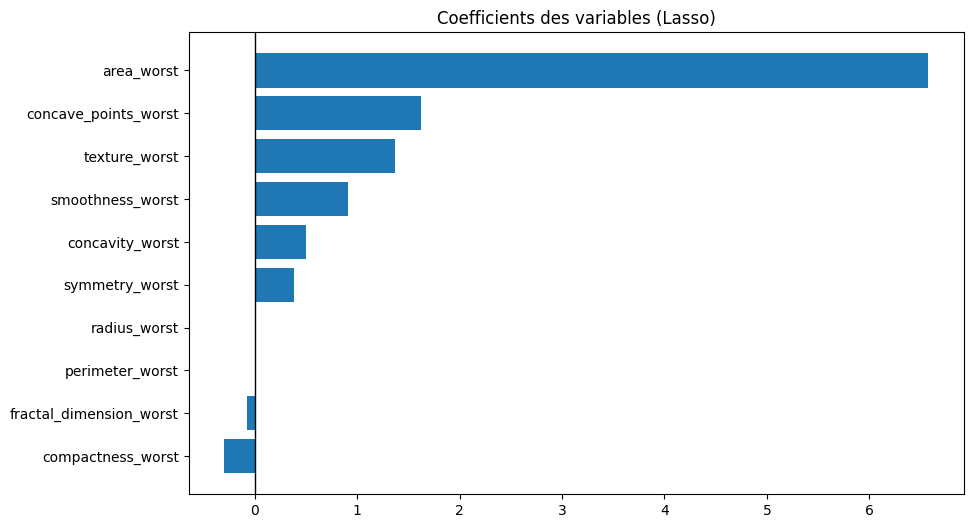

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Standardisation (très important pour Lasso)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Modèle Lasso (L1)
lasso = LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)
lasso.fit(X_scaled, y)

# Coefficients
coef = lasso.coef_.flatten()

# DataFrame
coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": coef
})

coef_df = coef_df.sort_values(by="Coefficient")

# Graphique
plt.figure(figsize=(10,6))
plt.barh(coef_df["Variable"], coef_df["Coefficient"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Coefficients des variables (Lasso)")
plt.show()

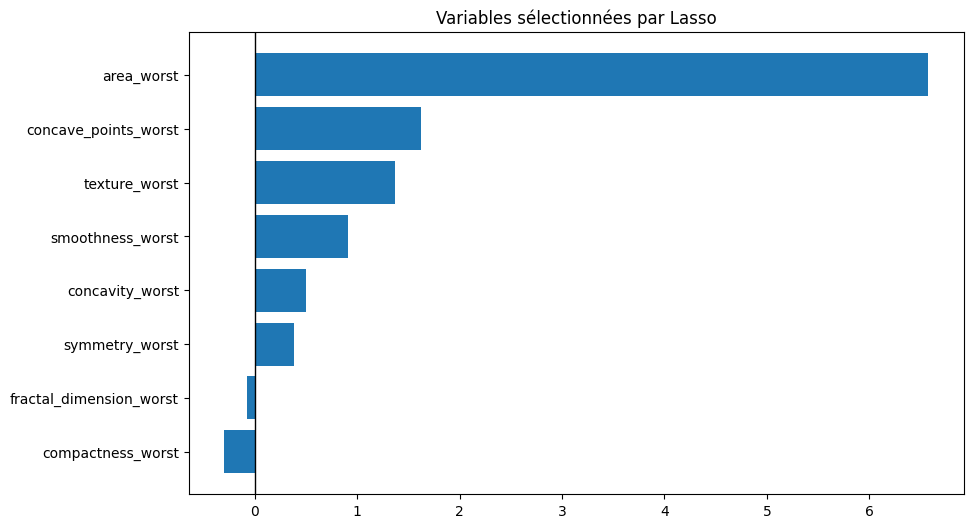

In [43]:
selected = coef_df[coef_df["Coefficient"] != 0]

plt.figure(figsize=(10,6))
plt.barh(selected["Variable"], selected["Coefficient"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Variables sélectionnées par Lasso")
plt.show()

---

### `Sélection de variables`

In [44]:
cancer_clean_new = cancer_clean.drop(["radius_worst", "perimeter_worst"], axis = 1)

# cancer_select = pd.DataFrame(cancer_clean[['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
#       'compactness_worst', 'concavity_worst', "diagnosis"]])


In [45]:
cancer_clean_new.head()

,diagnosis,texture_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
1,M,23.41,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,25.53,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
4,M,16.67,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,23.75,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,M,27.66,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368


---

### Conclusion 

Dans ce projet, notre objectif était de prédire la présence d’un cancer du sein chez des patientes à partir des caractéristiques cellulaires contenues dans le jeu de données. Pour cela, nous avons réalisé une analyse exploratoire approfondie des différentes variables. Les analyses ont mis en évidence des différences significatives entre les deux catégories de patientes. Les patientes atteintes d’un cancer du sein présentent généralement des cellules plus volumineuses ainsi que des formes plus irrégulières.

Parmi les variables les plus discriminantes liées à la taille des cellules, nous pouvons citer : radius_mean, perimeter_mean et area_mean.

Concernant les caractéristiques de forme, les variables suivantes se sont révélées particulièrement informatives : compactness_mean et concavity_mean.

L’étude des distributions et des corrélations a également montré que certaines variables présentent des comportements très similaires. Par exemple, radius_mean et perimeter_mean possèdent des distributions proches et sont fortement corrélées. Le même constat a été observé pour les variables concave_points_worst, concavity_worst et compactness_worst, qui traduisent des informations structurelles voisines sur la morphologie cellulaire.


---

### `Enregistrer les données sous format csv`

In [47]:
# Save data
cancer_clean_new.to_csv("Data/process/cancer_clean_new.csv", index=False) 